# Zadanie 1 — PenDigits

**Cel:** poznaj numeryczny zbiór danych, porównaj kilka uzasadnionych metod klasyfikacji statystycznej i uczenia maszynowego oraz oceń, czy większa złożoność modelu daje istotną korzyść.

In [1]:
# Proponowane importy — możesz je zmienić lub rozszerzyć.
from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from huggingface_hub import hf_hub_download
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [2]:
# Pobranie niezmienionego archiwum z oficjalnymi podziałami train/test.
DATA_DIR = Path("data/zadanie-1")
DATA_DIR.mkdir(parents=True, exist_ok=True)

archive_path = hf_hub_download(
    repo_id="AI-MED-AGH/Recruitment-Task-1",
    filename="original/pen+based+recognition+of+handwritten+digits.zip",
    repo_type="dataset",
    local_dir=DATA_DIR,
)
with ZipFile(archive_path) as archive:
    archive.extractall(DATA_DIR / "pendigits")

print(f"Dane zapisano w: {DATA_DIR / 'pendigits'}")

Dane zapisano w: data\zadanie-1\pendigits


## A — Poznanie i przygotowanie danych

Rozpoznaj zmienną docelową i cechy, sprawdź rozkład klas, braki, duplikaty oraz zakresy wartości. Pokaż krótką eksplorację danych i uzasadnij preprocessing. Zachowaj oficjalny podział danych; nie zastępuj go losowym podziałem.

In [3]:
train = pd.read_csv("data/zadanie-1/pendigits/pendigits.tra", header=None)
test = pd.read_csv("data/zadanie-1/pendigits/pendigits.tes", header=None)

x_train = train.iloc[:, :-1]
y_train = train.iloc[:, -1]

x_test = test.iloc[:, :-1]
y_test = test.iloc[:, -1]




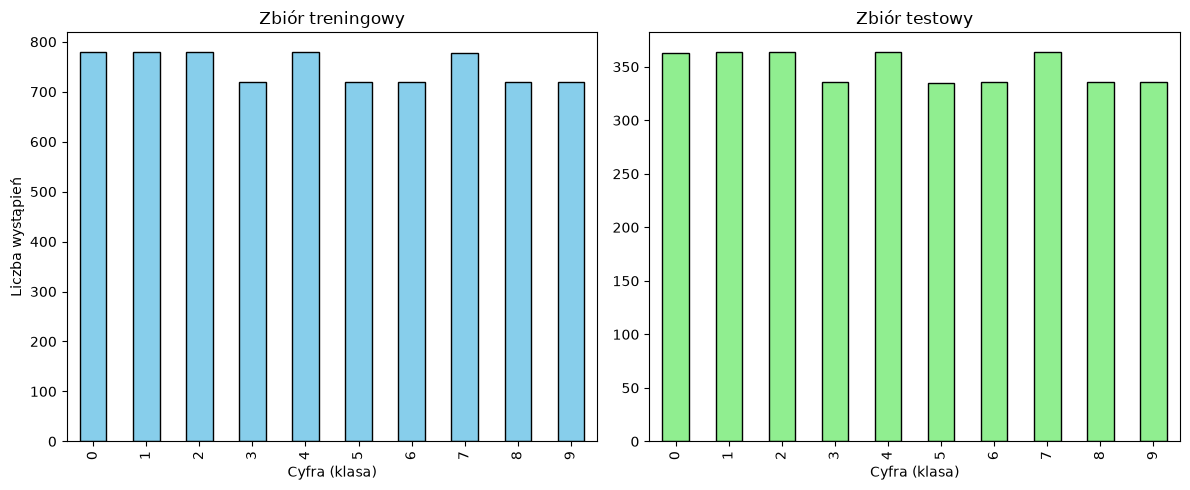

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

y_train.value_counts().sort_index().plot(kind='bar', ax=axes[0], color='skyblue', edgecolor='black')
axes[0].set_title("Zbiór treningowy")
axes[0].set_xlabel("Cyfra (klasa)")
axes[0].set_ylabel("Liczba wystąpień")

y_test.value_counts().sort_index().plot(kind='bar', ax=axes[1], color='lightgreen', edgecolor='black')
axes[1].set_title("Zbiór testowy")
axes[1].set_xlabel("Cyfra (klasa)")

plt.tight_layout() 
plt.show()

Rozkład klas jest zrównoważony.

In [5]:
print("brakujące wartośći")
print(train.isna().sum().sum())
print(test.isna().sum().sum())
print("duplikaty")
print(train.duplicated().sum())
print(test.duplicated().sum())
print("zakres wartosci")
display(x_train.describe().T)
display(x_test.describe().T)



brakujące wartośći
0
0
duplikaty
0
0
zakres wartosci


,count,mean,std,min,25%,50%,75%,max
0,7494.0,37.384307,33.322024,0.0,5.0,31.0,61.0,100.0
1,7494.0,84.679343,16.848420,0.0,76.0,89.0,100.0,100.0
2,7494.0,40.005604,26.256025,0.0,20.0,39.0,58.0,100.0
3,7494.0,82.889512,19.638582,0.0,70.0,89.0,100.0,100.0
4,7494.0,50.878303,34.927201,0.0,17.0,56.0,81.0,100.0
5,7494.0,65.044436,27.377341,0.0,48.0,71.0,86.0,100.0
6,7494.0,51.471844,30.680075,0.0,28.0,54.0,75.0,100.0
7,7494.0,44.599680,30.659478,0.0,22.0,42.0,65.0,100.0
8,7494.0,57.129971,33.680340,0.0,30.0,60.0,88.0,100.0
9,7494.0,34.069122,27.459989,0.0,7.0,33.0,55.0,100.0


,count,mean,std,min,25%,50%,75%,max
0,3498.0,41.877930,35.995293,0.0,8.0,34.0,75.0,100.0
1,3498.0,86.064894,14.737085,0.0,77.0,90.0,100.0,100.0
2,3498.0,41.891081,26.486364,0.0,22.0,42.0,60.0,100.0
3,3498.0,85.669525,17.960876,0.0,75.0,94.0,100.0,100.0
4,3498.0,47.396798,32.134722,0.0,19.0,49.0,73.0,100.0
5,3498.0,66.705832,26.130413,0.0,52.0,71.0,87.0,100.0
6,3498.0,50.681246,30.351970,0.0,29.0,52.0,73.0,100.0
7,3498.0,44.283305,28.227548,0.0,26.0,44.0,63.0,100.0
8,3498.0,56.308462,35.089176,0.0,26.0,59.0,91.0,100.0
9,3498.0,32.896512,26.785929,0.0,6.0,32.0,52.0,100.0


In [6]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [7]:
x_train_scaled_df = pd.DataFrame(x_train_scaled, columns=x_train.columns)
x_test_scaled_df = pd.DataFrame(x_test_scaled, columns=x_test.columns)

display(x_train_scaled_df.describe().round(2).T)
display(x_test_scaled_df.describe().round(2).T)

,count,mean,std,min,25%,50%,75%,max
0,7494.0,0.0,1.0,-1.12,-0.97,-0.19,0.71,1.88
1,7494.0,-0.0,1.0,-5.03,-0.52,0.26,0.91,0.91
2,7494.0,-0.0,1.0,-1.52,-0.76,-0.04,0.69,2.29
3,7494.0,0.0,1.0,-4.22,-0.66,0.31,0.87,0.87
4,7494.0,0.0,1.0,-1.46,-0.97,0.15,0.86,1.41
5,7494.0,-0.0,1.0,-2.38,-0.62,0.22,0.77,1.28
6,7494.0,0.0,1.0,-1.68,-0.77,0.08,0.77,1.58
7,7494.0,-0.0,1.0,-1.45,-0.74,-0.08,0.67,1.81
8,7494.0,0.0,1.0,-1.70,-0.81,0.09,0.92,1.27
9,7494.0,0.0,1.0,-1.24,-0.99,-0.04,0.76,2.40


,count,mean,std,min,25%,50%,75%,max
0,3498.0,0.13,1.08,-1.12,-0.88,-0.10,1.13,1.88
1,3498.0,0.08,0.87,-5.03,-0.46,0.32,0.91,0.91
2,3498.0,0.07,1.01,-1.52,-0.69,0.08,0.76,2.29
3,3498.0,0.14,0.91,-4.22,-0.40,0.57,0.87,0.87
4,3498.0,-0.10,0.92,-1.46,-0.91,-0.05,0.63,1.41
5,3498.0,0.06,0.95,-2.38,-0.48,0.22,0.80,1.28
6,3498.0,-0.03,0.99,-1.68,-0.73,0.02,0.70,1.58
7,3498.0,-0.01,0.92,-1.45,-0.61,-0.02,0.60,1.81
8,3498.0,-0.02,1.04,-1.70,-0.92,0.06,1.01,1.27
9,3498.0,-0.04,0.98,-1.24,-1.02,-0.08,0.65,2.40


### Uzasadnienie preprocessingu

**Cel skalowania:** Mimo że wszystkie cechy mieszczą się w zakresie 0-100, ich średnie drastycznie się różnią. Aby algorytmy nie faworyzowały kolumn o wyższych wartościach, zastosowano `StandardScaler`. Sprowadził on średnią każdej cechy do 0, a odchylenie do 1, wyrównując w ten sposób ich wpływ na model.


## B — Modelowanie

Zbuduj prosty model bazowy i porównaj go z kilkoma klasyfikatorami statystycznymi lub klasycznego uczenia maszynowego. Wykonaj dobór modeli, strojenie i sposób zapobiegania wyciekowi danych. 

In [8]:
from sklearn.dummy import DummyClassifier

dummy_model = DummyClassifier(strategy="most_frequent")
dummy_results = cross_validate(dummy_model, x_train_scaled, y_train, cv=5, scoring="accuracy")
dummy_accuracy = np.mean(dummy_results["test_score"])
print(f"Średnia dokładność modelu DummyClassifier: {dummy_accuracy:.4f}")


Średnia dokładność modelu DummyClassifier: 0.1041


In [9]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

pipe_knn = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

pipe_logreg = Pipeline([
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(max_iter=1000))
])

In [10]:

param_grid_knn = {
    "knn__n_neighbors": [3, 5, 7],
    "knn__weights": ["uniform", "distance"]
}

param_grid_logreg = {
    "logreg__C": [0.1, 1, 10],
}

grid_knn = GridSearchCV(pipe_knn, param_grid_knn, cv=5, scoring="accuracy", n_jobs=-1)
grid_logreg = GridSearchCV(pipe_logreg, param_grid_logreg, cv=5, scoring="accuracy", n_jobs=-1)

print("Strojenie knn")
grid_knn.fit(x_train, y_train)

print("Strojenie logreg")
grid_logreg.fit(x_train, y_train)

print("--- Wyniki k-NN ---")
print("Najlepsze parametry:", grid_knn.best_params_)
print(f"Skuteczność: {grid_knn.best_score_ * 100:.2f}%\n")

print("--- Wyniki Regresji Logistycznej ---")
print("Najlepsze parametry:", grid_logreg.best_params_)
print(f"Skuteczność: {grid_logreg.best_score_ * 100:.2f}%")

Strojenie knn


Strojenie logreg
--- Wyniki k-NN ---
Najlepsze parametry: {'knn__n_neighbors': 3, 'knn__weights': 'distance'}
Skuteczność: 99.43%

--- Wyniki Regresji Logistycznej ---
Najlepsze parametry: {'logreg__C': 10}
Skuteczność: 96.53%


## C — Porównanie i wnioski

Porównaj modele na oficjalnym zbiorze testowym za pomocą odpowiednich metryk liczbowych. Uwzględnij błędy oraz praktyczny koszt modeli, np. czas uczenia i inferencji albo liczbę parametrów. Odpowiedz, czy wzrost złożoności jest wart uzyskanej poprawy.

In [11]:
from sklearn.metrics import accuracy_score


y_pred_knn = grid_knn.predict(x_test)
y_pred_logreg = grid_logreg.predict(x_test)

acc_knn = accuracy_score(y_test, y_pred_knn)
acc_logreg = accuracy_score(y_test, y_pred_logreg)

print(f"Skuteczność k-NN: {acc_knn * 100:.2f}%")
print(f"Skuteczność Regresji Logistycznej: {acc_logreg * 100:.2f}%\n")

print("Raport dla k-NN (jak radził sobie z poszczególnymi cyframi):")
print(classification_report(y_test, y_pred_knn))

Skuteczność k-NN: 97.46%
Skuteczność Regresji Logistycznej: 92.82%

Raport dla k-NN (jak radził sobie z poszczególnymi cyframi):
              precision    recall  f1-score   support

           0       1.00      0.97      0.98       363
           1       0.95      0.95      0.95       364
           2       0.96      0.99      0.97       364
           3       0.97      0.99      0.98       336
           4       0.99      0.97      0.98       364
           5       0.96      0.98      0.97       335
           6       0.98      1.00      0.99       336
           7       0.98      0.95      0.97       364
           8       0.99      0.99      0.99       336
           9       0.98      0.95      0.96       336

    accuracy                           0.97      3498
   macro avg       0.97      0.97      0.97      3498
weighted avg       0.97      0.97      0.97      3498



In [12]:
print("Raport dla Regresji Logistycznej (jak radził sobie z poszczególnymi cyframi):")
print(classification_report(y_test, y_pred_logreg))

Raport dla Regresji Logistycznej (jak radził sobie z poszczególnymi cyframi):
              precision    recall  f1-score   support

           0       0.97      0.89      0.93       363
           1       0.86      0.90      0.88       364
           2       0.96      0.98      0.97       364
           3       0.98      0.99      0.98       336
           4       0.95      0.97      0.96       364
           5       0.84      0.95      0.89       335
           6       0.96      0.96      0.96       336
           7       0.98      0.83      0.90       364
           8       0.84      0.88      0.86       336
           9       0.96      0.93      0.95       336

    accuracy                           0.93      3498
   macro avg       0.93      0.93      0.93      3498
weighted avg       0.93      0.93      0.93      3498



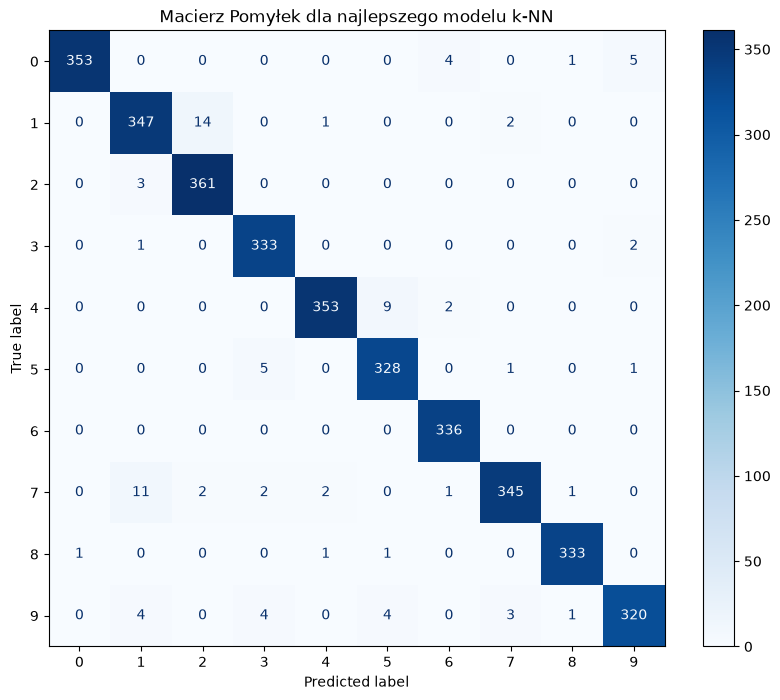

In [13]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    y_test,              
    y_pred_knn,          
    cmap='Blues',        
    ax=ax
)

plt.title("Macierz Pomyłek dla najlepszego modelu k-NN")
plt.show()

Model k-NN myli się rzadko, a jego błędy wynikają z naturalnego podobieństwa cyfr w odręcznym piśmie. Z macierzy pomyłek wynika, że algorytm najczęściej mylił jedynkę z dwójką (14 razy) oraz siódemkę z jedynką (11 razy), co dla surowych współrzędnych geometrycznych z rysika jest w pełni uzasadnione.

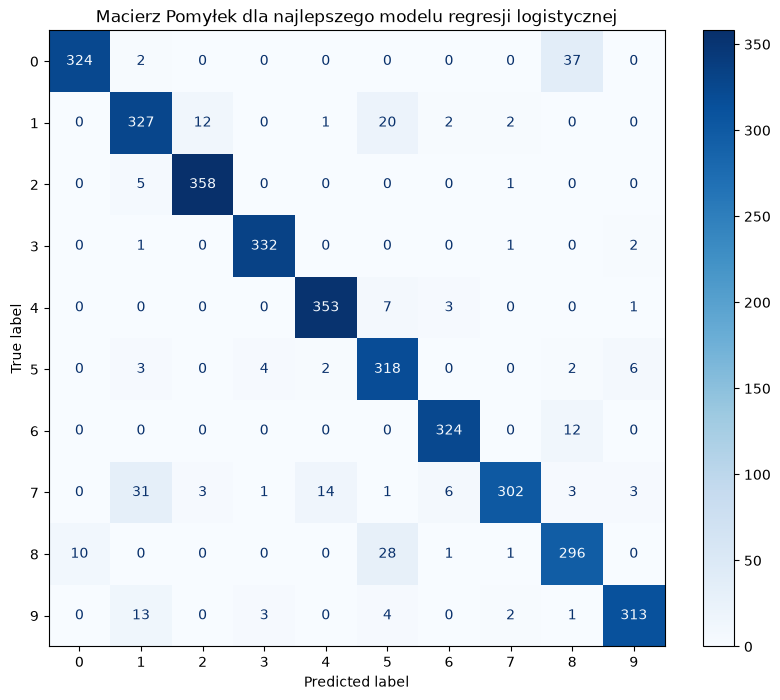

In [14]:
fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    y_test,              
    y_pred_logreg,          
    cmap='Blues',        
    ax=ax
)

plt.title("Macierz Pomyłek dla najlepszego modelu regresji logistycznej")
plt.show()

Słabszy wynik Regresji Logistycznej wynika z liniowej natury tego algorytmu. Regresja próbuje oddzielić klasy cyfr za pomocą sztywnych, płaskich granic decyzyjnych (hiperpłaszczyzn). Tymczasem ruchy rysika dla cyfr takich jak '0' i '8' w 16-wymiarowej przestrzeni tworzą skomplikowane, nakładające się na siebie zbiory nieliniowe. Prosta linia graniczna regresji nie jest w stanie owinąć się wokół tych kształtów, co skutkuje aż 37 pomyłkami między '0' a '8'. Model k-NN nie ma tego problemu, ponieważ nie rysuje globalnych granic, lecz elastycznie szuka najbliższego sąsiada w swoim bezpośrednim otoczeniu, co jest znacznie lepszą strategią dla odręcznego pisma.

In [15]:
import time

best_knn = grid_knn.best_estimator_
best_logreg = grid_logreg.best_estimator_

start = time.time()
best_knn.fit(x_train, y_train)
knn_train_time = time.time() - start

start = time.time()
best_logreg.fit(x_train, y_train)
logreg_train_time = time.time() - start

start = time.time()
best_knn.predict(x_test)
knn_test_time = time.time() - start

start = time.time()
best_logreg.predict(x_test)
logreg_test_time = time.time() - start

print("--- KOSZT PRAKTYCZNY MODELI ---")
print(f"k-NN              -> Czas uczenia: {knn_train_time:.4f} s | Czas inferencji: {knn_test_time:.4f} s")
print(f"Reg. Logistyczna  -> Czas uczenia: {logreg_train_time:.4f} s | Czas inferencji: {logreg_test_time:.4f} s")

--- KOSZT PRAKTYCZNY MODELI ---
k-NN              -> Czas uczenia: 0.0115 s | Czas inferencji: 0.0464 s
Reg. Logistyczna  -> Czas uczenia: 0.2077 s | Czas inferencji: 0.0037 s


In [16]:
import pickle

knn_bytes = pickle.dumps(best_knn)
logreg_bytes = pickle.dumps(best_logreg)

knn_size_kb = len(knn_bytes) / 1024
logreg_size_kb = len(logreg_bytes) / 1024

print("--- ROZMIAR MODELI W PAMIĘCI (KOSZT ZAPISU) ---")
print(f"Waga k-NN: {knn_size_kb:.2f} KB")
print(f"Waga Regresji Logistycznej: {logreg_size_kb:.2f} KB")

--- ROZMIAR MODELI W PAMIĘCI (KOSZT ZAPISU) ---
Waga k-NN: 996.76 KB
Waga Regresji Logistycznej: 2.80 KB


Czy warto?  
Na standardowym sprzęcie (TAK): Jeśli tworzymy system rozpoznawania pisma na komputer, tablet medyczny czy współczesny smartfon, odpowiedź brzmi: absolutnie tak. Zdobyliśmy dodatkowe 5 punktów procentowych skuteczności (i zredukowaliśmy błędy prawie trzykrotnie), a rachunek w postaci 1 MB pamięci i 0.05 s opóźnienia to dla dzisiejszych procesorów wartość mikroskopijna, całkowicie niezauważalna dla użytkownika.

W systemach wbudowanych (NIE): Gdybyśmy jednak chcieli wgrać ten model na tani, energooszczędny mikrokontroler (np. STM32) wbudowany w przenośny długopis medyczny, to zablokowanie 1 MB pamięci RAM dla samego modelu byłoby technicznie niemożliwe. W takim rygorystycznym środowisku wzrost złożoności k-NN go dyskwalifikuje i musielibyśmy zadowolić się mniejszą skutecznością Regresji Logistycznej na korzyść jej ultralekkiej wagi.

## Oddanie zadania

Zapisz kod, wyniki, wykresy i krótkie uzasadnienia w tym notatniku. Podaj użyte źródła oraz narzędzia AI i upewnij się, że notatnik można uruchomić od początku do końca. Wykonaj commit po zakończeniu zadania aby znalazł się na repozytorium.

narzędzia:

- gemini
- copilot